In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU: []


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import pickle
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    SimpleRNN,
    LSTM,
    GRU,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

print("Everything imported successfully")

Everything imported successfully


In [3]:
import os

print(os.listdir())

['.config', 'labelled_newscatcher_dataset.csv', 'sample_data']


In [25]:
import pandas as pd

df = pd.read_csv(
    "/content/labelled_newscatcher_dataset.csv",
    sep=";"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (108774, 6)


In [26]:
print(df.columns.tolist())

['topic', 'link', 'domain', 'published_date', 'title', 'lang']


In [27]:
df.head()

,topic,link,domain,published_date,title,lang
0,SCIENCE,https://www.eurekalert.org/pub_releases/2020-0...,eurekalert.org,2020-08-06 13:59:45,A closer look at water-splitting's solar fuel ...,en
1,SCIENCE,https://www.pulse.ng/news/world/an-irresistibl...,pulse.ng,2020-08-12 15:14:19,"An irresistible scent makes locusts swarm, stu...",en
2,SCIENCE,https://www.express.co.uk/news/science/1322607...,express.co.uk,2020-08-13 21:01:00,Artificial intelligence warning: AI will know ...,en
3,SCIENCE,https://www.ndtv.com/world-news/glaciers-could...,ndtv.com,2020-08-03 22:18:26,Glaciers Could Have Sculpted Mars Valleys: Study,en
4,SCIENCE,https://www.thesun.ie/tech/5742187/perseid-met...,thesun.ie,2020-08-12 19:54:36,Perseid meteor shower 2020: What time and how ...,en


In [28]:
print("Dataset Shape:", df.shape)

print("\nCategories:")
print(df["topic"].value_counts())

print("\nNumber of Categories:")
print(df["topic"].nunique())

Dataset Shape: (108774, 6)

Categories:
topic
TECHNOLOGY       15000
HEALTH           15000
WORLD            15000
ENTERTAINMENT    15000
BUSINESS         15000
SPORTS           15000
NATION           15000
SCIENCE           3774
Name: count, dtype: int64

Number of Categories:
8


In [29]:
print(df.isnull().sum())

topic             0
link              0
domain            0
published_date    0
title             0
lang              0
dtype: int64


In [30]:
df = df[
    ["title", "topic"]
].copy()

df.head()

,title,topic
0,A closer look at water-splitting's solar fuel ...,SCIENCE
1,"An irresistible scent makes locusts swarm, stu...",SCIENCE
2,Artificial intelligence warning: AI will know ...,SCIENCE
3,Glaciers Could Have Sculpted Mars Valleys: Study,SCIENCE
4,Perseid meteor shower 2020: What time and how ...,SCIENCE


In [31]:
df.shape

(108774, 2)

In [32]:
df = df.dropna(
    subset=["title", "topic"]
)

In [33]:
print(
    "Duplicates before:",
    df.duplicated(subset=["title"]).sum()
)

df = df.drop_duplicates(
    subset=["title"]
)

print(
    "Duplicates after:",
    df.duplicated(subset=["title"]).sum()
)

Duplicates before: 5594
Duplicates after: 0


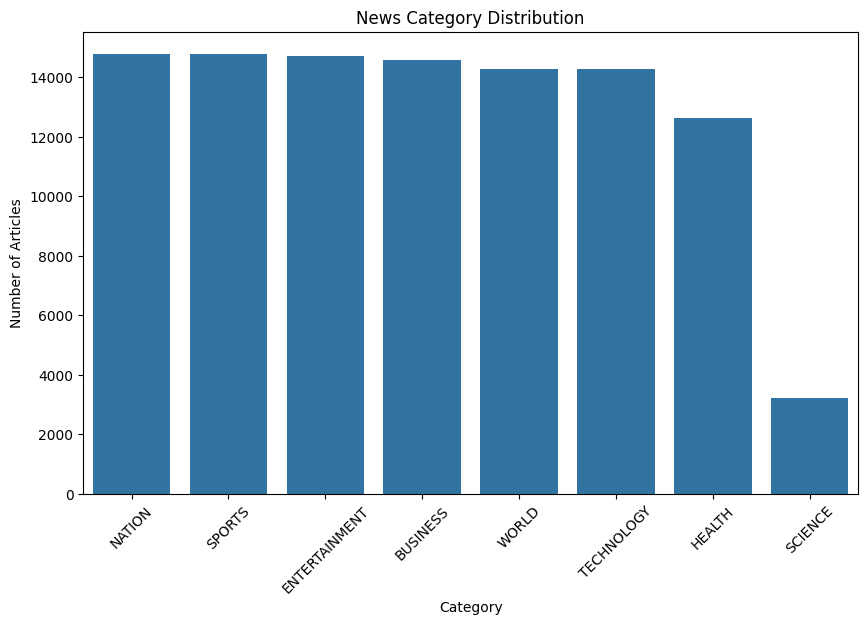

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x="topic",
    order=df["topic"].value_counts().index
)

plt.xticks(rotation=45)

plt.title("News Category Distribution")

plt.xlabel("Category")
plt.ylabel("Number of Articles")

plt.show()

In [35]:
print(df.shape)
print(df["topic"].value_counts())

(103180, 2)
topic
NATION           14777
SPORTS           14757
ENTERTAINMENT    14722
BUSINESS         14576
WORLD            14255
TECHNOLOGY       14255
HEALTH           12608
SCIENCE           3230
Name: count, dtype: int64


In [36]:
import re

In [37]:
print(df.columns.tolist())

['title', 'topic']


In [38]:
def clean_text(text):
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [39]:
df["clean_title"] = df["title"].apply(clean_text)

In [40]:
df[["title", "clean_title", "topic"]].head()

,title,clean_title,topic
0,A closer look at water-splitting's solar fuel ...,a closer look at water splitting s solar fuel ...,SCIENCE
1,"An irresistible scent makes locusts swarm, stu...",an irresistible scent makes locusts swarm stud...,SCIENCE
2,Artificial intelligence warning: AI will know ...,artificial intelligence warning ai will know u...,SCIENCE
3,Glaciers Could Have Sculpted Mars Valleys: Study,glaciers could have sculpted mars valleys study,SCIENCE
4,Perseid meteor shower 2020: What time and how ...,perseid meteor shower what time and how to see...,SCIENCE


In [41]:
df = df[
    df["clean_title"].str.len() > 0
].copy()

print(df.shape)

(103180, 3)


In [42]:
df = df[
    df["clean_title"].str.len() > 0
].copy()

In [43]:
print(df.shape)

(103180, 3)


In [44]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(
    df["topic"]
)

In [45]:
for i, category in enumerate(
    label_encoder.classes_
):
    print(i, "→", category)

0 → BUSINESS
1 → ENTERTAINMENT
2 → HEALTH
3 → NATION
4 → SCIENCE
5 → SPORTS
6 → TECHNOLOGY
7 → WORLD


**STEP 10 — Separate X and y**

In [46]:
X = df["clean_title"]

y = df["label"]

In [47]:
print("X:", X.shape)
print("y:", y.shape)

X: (103180,)
y: (103180,)


**STEP 11 — Train / Validation / Test Split**

In [48]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [49]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [50]:
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 82544
Validation: 10318
Testing: 10318


**STEP 12 — Verify class distribution after splitting**

In [51]:
print("TRAIN:")
print(y_train.value_counts().sort_index())

print("\nVALIDATION:")
print(y_val.value_counts().sort_index())

print("\nTEST:")
print(y_test.value_counts().sort_index())

TRAIN:
label
0    11661
1    11778
2    10086
3    11822
4     2584
5    11805
6    11404
7    11404
Name: count, dtype: int64

VALIDATION:
label
0    1457
1    1472
2    1261
3    1478
4     323
5    1476
6    1425
7    1426
Name: count, dtype: int64

TEST:
label
0    1458
1    1472
2    1261
3    1477
4     323
5    1476
6    1426
7    1425
Name: count, dtype: int64


**STEP 13 — Tokenization**

In [52]:
from tensorflow.keras.preprocessing.text import Tokenizer

In [53]:
MAX_WORDS = 30000

In [54]:
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

In [55]:
tokenizer.fit_on_texts(
    X_train
)

**STEP 14 — Convert text to sequences**

In [56]:
X_train_seq = tokenizer.texts_to_sequences(
    X_train
)

X_val_seq = tokenizer.texts_to_sequences(
    X_val
)

X_test_seq = tokenizer.texts_to_sequences(
    X_test
)

In [57]:
print(X_train.iloc[0])
print(X_train_seq[0])

thoughts on lets your documents go virtual
[3088, 9, 2125, 83, 2400, 220, 745]


**STEP 15 — Check title lengths**

In [58]:
lengths = [
    len(seq)
    for seq in X_train_seq
]

print(
    "Minimum:",
    np.min(lengths)
)

print(
    "Maximum:",
    np.max(lengths)
)

print(
    "Average:",
    np.mean(lengths)
)

print(
    "95th percentile:",
    np.percentile(lengths, 95)
)

Minimum: 1
Maximum: 51
Average: 11.45549040511727
95th percentile: 18.0


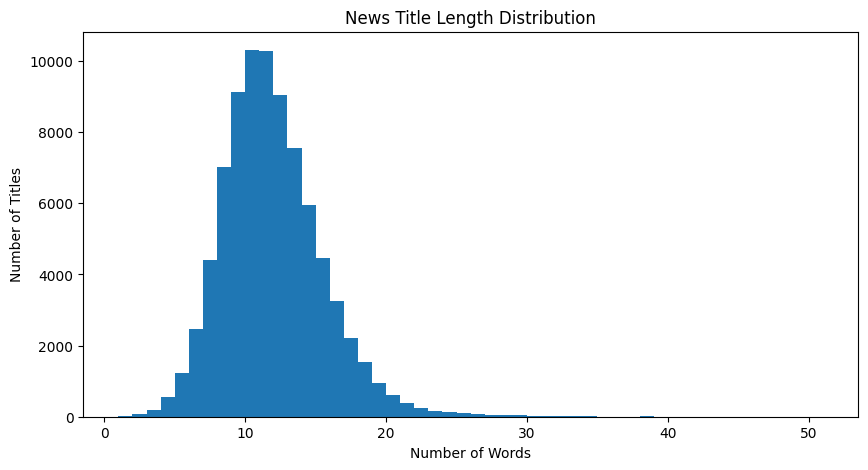

In [59]:
plt.figure(figsize=(10,5))

plt.hist(
    lengths,
    bins=50
)

plt.xlabel("Number of Words")
plt.ylabel("Number of Titles")

plt.title(
    "News Title Length Distribution"
)

plt.show()

**STEP 16 — Choose MAX_LEN**

In [60]:
MAX_LEN = 30

**STEP 17 — Padding**

In [61]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

Training:

In [62]:
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

Validation:

In [63]:
X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

Testing:

In [64]:

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

Check:

In [65]:
print(
    "Training shape:",
    X_train_pad.shape
)

print(
    "Validation shape:",
    X_val_pad.shape
)

print(
    "Testing shape:",
    X_test_pad.shape
)

Training shape: (82544, 30)
Validation shape: (10318, 30)
Testing shape: (10318, 30)


**STEP 18 — Vocabulary size**

In [66]:
vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

print(
    "Vocabulary size:",
    vocab_size
)

Vocabulary size: 30000


**STEP 19 — Calculate class weights**

In [67]:
from sklearn.utils.class_weight import compute_class_weight

In [68]:
classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

In [69]:
class_weight_dict = dict(
    zip(
        classes,
        class_weights
    )
)

In [70]:
print(class_weight_dict)

{np.int64(0): np.float64(0.8848297744618815), np.int64(1): np.float64(0.8760400747155714), np.int64(2): np.float64(1.0230021812413246), np.int64(3): np.float64(0.8727795635256301), np.int64(4): np.float64(3.9930340557275543), np.int64(5): np.float64(0.8740364252435409), np.int64(6): np.float64(0.9047702560505086), np.int64(7): np.float64(0.9047702560505086)}


**STEP 20 — Convert labels to NumPy**

In [71]:
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

In [72]:
num_classes = len(
    label_encoder.classes_
)

print(
    "Number of classes:",
    num_classes
)

Number of classes: 8


In [73]:
print(X_train_pad.shape)
print(X_val_pad.shape)
print(X_test_pad.shape)
print(vocab_size)
print(num_classes)

(82544, 30)
(10318, 30)
(10318, 30)
30000
8


**STEP 21 — Import TensorFlow/Keras**

In [74]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU: []


**STEP 22 — Create common settings**

In [75]:
EMBEDDING_DIM = 128
RNN_UNITS = 128
DENSE_UNITS = 64
DROPOUT_RATE = 0.5

**STEP 23 — Build Simple RNN**

In [76]:
from tensorflow.keras.layers import Input

def build_rnn_model():

    model = Sequential([

        Input(shape=(MAX_LEN,)),

        Embedding(
            input_dim=vocab_size,
            output_dim=EMBEDDING_DIM
        ),

        SimpleRNN(RNN_UNITS),

        Dropout(DROPOUT_RATE),

        Dense(
            DENSE_UNITS,
            activation="relu"
        ),

        Dropout(0.3),

        Dense(
            num_classes,
            activation="softmax"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [77]:
rnn_model = build_rnn_model()

In [78]:
rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 30, 128)        │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,881,672 (14.81 MB)

 Trainable params: 3,881,672 (14.81 MB)

 Non-trainable params: 0 (0.00 B)

**STEP 24 — Create callbacks**

In [79]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

In [80]:
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-6
)

**STEP 25 — Train RNN**

In [81]:
EPOCHS = 10
BATCH_SIZE = 128

In [85]:
import time

rnn_start = time.time()

rnn_history = rnn_model.fit(

    X_train_pad,
    y_train,

    validation_data=(
        X_val_pad,
        y_val
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    class_weight=class_weight_dict,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

rnn_time = time.time() - rnn_start

print(
    f"RNN training time: {rnn_time:.2f} seconds"
)

Epoch 1/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 47s 72ms/step - accuracy: 0.8027 - loss: 0.5764 - val_accuracy: 0.7065 - val_loss: 0.8723 - learning_rate: 2.5000e-04
Epoch 2/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 47s 72ms/step - accuracy: 0.8417 - loss: 0.4681 - val_accuracy: 0.7126 - val_loss: 0.8989 - learning_rate: 2.5000e-04
Epoch 3/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 46s 72ms/step - accuracy: 0.8774 - loss: 0.3737 - val_accuracy: 0.7153 - val_loss: 0.9404 - learning_rate: 1.2500e-04
RNN training time: 140.01 seconds


In [86]:
class_weight=class_weight_dict

**STEP 26 — Evaluate RNN**

In [87]:
rnn_loss, rnn_accuracy = rnn_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print(
    f"RNN Test Accuracy: {rnn_accuracy:.4f}"
)

RNN Test Accuracy: 0.7131


**STEP 27 — RNN predictions**

In [88]:
rnn_probabilities = rnn_model.predict(
    X_test_pad,
    verbose=0
)

rnn_predictions = np.argmax(
    rnn_probabilities,
    axis=1
)

Classification report:

In [89]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        rnn_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

               precision    recall  f1-score   support

     BUSINESS       0.77      0.70      0.74      1458
ENTERTAINMENT       0.85      0.79      0.82      1472
       HEALTH       0.62      0.73      0.67      1261
       NATION       0.62      0.52      0.56      1477
      SCIENCE       0.63      0.80      0.70       323
       SPORTS       0.82      0.88      0.85      1476
   TECHNOLOGY       0.83      0.82      0.83      1426
        WORLD       0.50      0.52      0.51      1425

     accuracy                           0.71     10318
    macro avg       0.71      0.72      0.71     10318
 weighted avg       0.72      0.71      0.71     10318



**STEP 28 — Build LSTM**

In [90]:
def build_lstm_model():

    model = Sequential([

        Embedding(
            input_dim=vocab_size,
            output_dim=EMBEDDING_DIM
        ),

        LSTM(
            RNN_UNITS
        ),

        Dropout(
            DROPOUT_RATE
        ),

        Dense(
            DENSE_UNITS,
            activation="relu"
        ),

        Dropout(
            0.3
        ),

        Dense(
            num_classes,
            activation="softmax"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

Create:

In [91]:
lstm_model = build_lstm_model()

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [92]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout

def build_lstm_model():

    model = Sequential([

        Input(shape=(MAX_LEN,)),

        Embedding(
            input_dim=vocab_size,
            output_dim=EMBEDDING_DIM
        ),

        LSTM(
            RNN_UNITS
        ),

        Dropout(
            DROPOUT_RATE
        ),

        Dense(
            DENSE_UNITS,
            activation="relu"
        ),

        Dropout(
            0.3
        ),

        Dense(
            num_classes,
            activation="softmax"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [93]:
lstm_model = build_lstm_model()

In [94]:
lstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 30, 128)        │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,980,360 (15.18 MB)

 Trainable params: 3,980,360 (15.18 MB)

 Non-trainable params: 0 (0.00 B)

**STEP 29 — Train LSTM**

In [95]:
lstm_start = time.time()

lstm_history = lstm_model.fit(

    X_train_pad,
    y_train,

    validation_data=(
        X_val_pad,
        y_val
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    class_weight=class_weight_dict,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

lstm_time = time.time() - lstm_start

print(
    f"LSTM training time: {lstm_time:.2f} seconds"
)

Epoch 1/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 87s 131ms/step - accuracy: 0.4214 - loss: 1.4459 - val_accuracy: 0.6751 - val_loss: 0.8742 - learning_rate: 0.0010
Epoch 2/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 84s 130ms/step - accuracy: 0.7415 - loss: 0.6959 - val_accuracy: 0.7412 - val_loss: 0.7700 - learning_rate: 5.0000e-04
Epoch 3/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 85s 131ms/step - accuracy: 0.8143 - loss: 0.5379 - val_accuracy: 0.7803 - val_loss: 0.7079 - learning_rate: 5.0000e-04
Epoch 4/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 140s 129ms/step - accuracy: 0.8557 - loss: 0.4433 - val_accuracy: 0.7871 - val_loss: 0.7262 - learning_rate: 5.0000e-04
Epoch 5/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 84s 130ms/step - accuracy: 0.8924 - loss: 0.3414 - val_accuracy: 0.7878 - val_loss: 0.7683 - learning_rate: 2.5000e-04
LSTM training time: 479.44 seconds


**STEP 30 — Evaluate LSTM**

In [96]:
lstm_loss, lstm_accuracy = lstm_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print(
    f"LSTM Test Accuracy: {lstm_accuracy:.4f}"
)

LSTM Test Accuracy: 0.7791


Predictions:

In [97]:
lstm_probabilities = lstm_model.predict(
    X_test_pad,
    verbose=0
)

lstm_predictions = np.argmax(
    lstm_probabilities,
    axis=1
)

Classification report:

In [98]:
print(
    classification_report(
        y_test,
        lstm_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

               precision    recall  f1-score   support

     BUSINESS       0.81      0.77      0.79      1458
ENTERTAINMENT       0.77      0.92      0.84      1472
       HEALTH       0.75      0.78      0.77      1261
       NATION       0.61      0.67      0.64      1477
      SCIENCE       0.77      0.80      0.79       323
       SPORTS       0.92      0.87      0.90      1476
   TECHNOLOGY       0.91      0.86      0.88      1426
        WORLD       0.69      0.56      0.62      1425

     accuracy                           0.78     10318
    macro avg       0.78      0.78      0.78     10318
 weighted avg       0.78      0.78      0.78     10318



**STEP 31 — Build GRU**

In [99]:
def build_gru_model():

    model = Sequential([

        Embedding(
            input_dim=vocab_size,
            output_dim=EMBEDDING_DIM
        ),

        GRU(
            RNN_UNITS
        ),

        Dropout(
            DROPOUT_RATE
        ),

        Dense(
            DENSE_UNITS,
            activation="relu"
        ),

        Dropout(
            0.3
        ),

        Dense(
            num_classes,
            activation="softmax"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

Create:

In [100]:
gru_model = build_gru_model()

gru_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

**STEP 32 — Train GRU**

In [101]:
gru_model = build_gru_model()

In [102]:
gru_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

gru_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-6
)

In [107]:
import time

gru_start = time.time()

gru_history = gru_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=128,
    class_weight=class_weight_dict,
    callbacks=[
        gru_early_stopping,
        gru_reduce_lr
    ],
    verbose=1
)

gru_time = time.time() - gru_start

print(f"GRU training time: {gru_time:.2f} seconds")

Epoch 1/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 84s 131ms/step - accuracy: 0.8543 - loss: 0.4397 - val_accuracy: 0.7828 - val_loss: 0.7135 - learning_rate: 2.5000e-04
Epoch 2/10
645/645 ━━━━━━━━━━━━━━━━━━━━ 145s 136ms/step - accuracy: 0.8750 - loss: 0.3808 - val_accuracy: 0.7838 - val_loss: 0.7310 - learning_rate: 1.2500e-04
GRU training time: 229.81 seconds


In [104]:
gru_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 30, 128)        │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 128)            │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,843,546 (45.18 MB)

 Trainable params: 3,947,848 (15.06 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,895,698 (30.12 MB)

**STEP 33 — Evaluate GRU**

In [108]:
gru_loss, gru_accuracy = gru_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print(
    f"GRU Test Accuracy: {gru_accuracy:.4f}"
)

GRU Test Accuracy: 0.7875


Predictions:

In [109]:
gru_probabilities = gru_model.predict(
    X_test_pad,
    verbose=0
)

gru_predictions = np.argmax(
    gru_probabilities,
    axis=1
)

Classification report:

In [110]:
print(
    classification_report(
        y_test,
        gru_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

               precision    recall  f1-score   support

     BUSINESS       0.81      0.77      0.79      1458
ENTERTAINMENT       0.83      0.90      0.86      1472
       HEALTH       0.70      0.82      0.75      1261
       NATION       0.64      0.68      0.66      1477
      SCIENCE       0.73      0.85      0.78       323
       SPORTS       0.94      0.90      0.92      1476
   TECHNOLOGY       0.90      0.86      0.88      1426
        WORLD       0.73      0.57      0.64      1425

     accuracy                           0.79     10318
    macro avg       0.78      0.79      0.79     10318
 weighted avg       0.79      0.79      0.79     10318



**STEP 34 — Compare RNN, LSTM and GRU**

In [111]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

models_predictions = {
    "RNN": rnn_predictions,
    "LSTM": lstm_predictions,
    "GRU": gru_predictions
}

training_times = {
    "RNN": rnn_time,
    "LSTM": lstm_time,
    "GRU": gru_time
}

for model_name, predictions in models_predictions.items():

    results.append({

        "Model": model_name,

        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Training Time (sec)": training_times[
            model_name
        ]
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (sec)
0,GRU,0.787459,0.790244,0.787459,0.786342,229.808213
1,LSTM,0.779124,0.781719,0.779124,0.778041,479.435644
2,RNN,0.713123,0.716376,0.713123,0.712597,140.011766


**STEP 35 — Visual comparison**

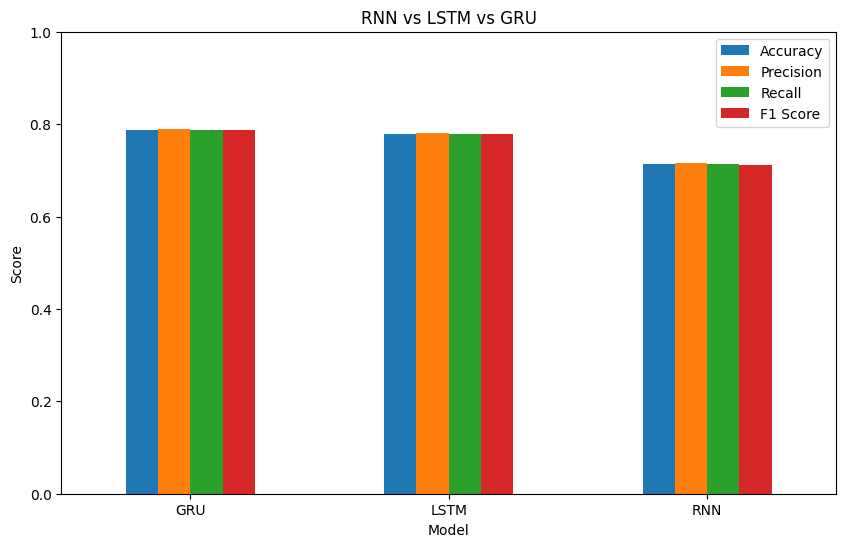

In [112]:
comparison_df.set_index(
    "Model"
)[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
].plot(
    kind="bar",
    figsize=(10,6)
)

plt.title(
    "RNN vs LSTM vs GRU"
)

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.show()

**STEP 36 — Select the best model**

In [113]:
best_model_name = comparison_df.iloc[0]["Model"]

print(
    "Best Model:",
    best_model_name
)

Best Model: GRU


In [114]:
if best_model_name == "RNN":

    best_model = rnn_model
    best_predictions = rnn_predictions

elif best_model_name == "LSTM":

    best_model = lstm_model
    best_predictions = lstm_predictions

else:

    best_model = gru_model
    best_predictions = gru_predictions

**STEP 37 — Confusion Matrix of Best Model**

In [115]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

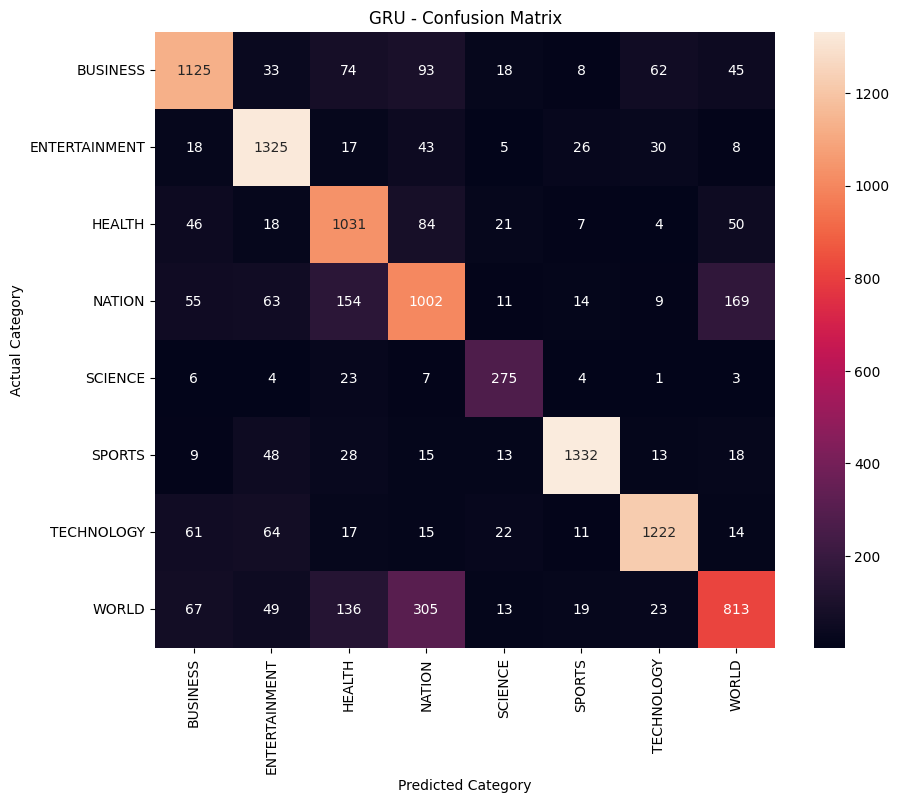

In [116]:
cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Category")

plt.ylabel("Actual Category")

plt.title(
    f"{best_model_name} - Confusion Matrix"
)

plt.show()

**STEP 38 — Save the best model**

In [117]:
import os

os.makedirs(
    "saved_model",
    exist_ok=True
)

In [118]:
best_model.save(
    "saved_model/best_news_classifier.keras"
)

**STEP 39 — Save tokenizer**

In [119]:
import pickle

with open(
    "saved_model/tokenizer.pkl",
    "wb"
) as file:

    pickle.dump(
        tokenizer,
        file
    )

**STEP 40 — Save label encoder**

In [120]:
with open(
    "saved_model/label_encoder.pkl",
    "wb"
) as file:

    pickle.dump(
        label_encoder,
        file
    )

**STEP 41 — Test the final model**

In [121]:
def predict_news(text):

    # Clean text
    text = clean_text(text)

    # Convert to sequence
    sequence = tokenizer.texts_to_sequences(
        [text]
    )

    # Padding
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Prediction
    probabilities = best_model.predict(
        padded,
        verbose=0
    )[0]

    # Best class
    predicted_class = np.argmax(
        probabilities
    )

    # Convert number → category
    category = label_encoder.inverse_transform(
        [predicted_class]
    )[0]

    # Confidence
    confidence = probabilities[
        predicted_class
    ]

    return category, confidence

In [122]:
news = """
India wins a thrilling cricket match against
Australia in the international series
"""

category, confidence = predict_news(news)

print("Predicted Category:", category)
print("Confidence:", f"{confidence:.2%}")

Predicted Category: SPORTS
Confidence: 98.17%
